# Día 4 · Los otros tres intervalos: media, diferencia de proporciones y diferencia de medias

**Apartado del documento que cubre este día:** 5 (Estimación por intervalo), segunda parte.

**Al terminar este día, cada integrante del equipo debe poder explicar sin leer:**
1. Que los cuatro intervalos siguen la misma estructura: estimación ± valor crítico × error estándar.
2. Por qué el intervalo de la media usa la distribución t y no z.
3. Por qué se puede usar ese intervalo aunque los saldos no tengan forma de campana.
4. Cómo se lee el intervalo de una diferencia: si contiene o no contiene el 0.
5. Qué es el método de Welch y por qué se eligió.
6. La diferencia entre "estadísticamente significativo" y "importante en la práctica".

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "clases" else Path.cwd()
poblacion = pd.read_csv(RAIZ / "data" / "processed" / "poblacion_clientes.csv")
muestra = pd.read_csv(RAIZ / "data" / "processed" / "muestra_clientes_n1000.csv")
N = len(poblacion)
n = len(muestra)
print("Clientes en la población (N):", N)
print("Clientes en la muestra (n):", n)

Clientes en la población (N): 10000
Clientes en la muestra (n): 1000


---
## Paso 1 · Qué pide el documento y la estructura común

El documento pide al menos dos técnicas de estimación elegidas según el tipo de datos, entre: media, diferencia de medias, proporción y diferencia de proporciones. El proyecto usa las cuatro.

Los cuatro intervalos tienen la misma estructura:

$$\text{intervalo} = \text{estimación} \pm \text{valor crítico} \times \text{error estándar} \times \text{FCPF}$$

| Pregunta | Estimación | Valor crítico | Error estándar |
|---|---|---|---|
| P1 · proporción (Día 3) | $\hat p$ | $z$ = 1.96 | $\sqrt{\hat p(1-\hat p)/n}$ |
| P2 · media | $\bar x$ | $t$ | $s/\sqrt n$ |
| P3 · diferencia de proporciones | $\hat p_1 - \hat p_2$ | $z$ = 1.96 | $\sqrt{\hat p_1(1-\hat p_1)/n_1 + \hat p_2(1-\hat p_2)/n_2}$ |
| P4 · diferencia de medias | $\bar x_1 - \bar x_2$ | $t$ (Welch) | $\sqrt{s_1^2/n_1 + s_2^2/n_2}$ |

El factor de corrección por población finita (FCPF) es el mismo en los cuatro, porque cada grupo es cerca del 10 % de su grupo en la población.

In [2]:
fcpf = np.sqrt((N - n) / (N - 1))
z_critico = stats.norm.ppf(0.975)
print("FCPF:", round(fcpf, 4))
print("Valor crítico z para 95 %:", round(z_critico, 4))

FCPF: 0.9487
Valor crítico z para 95 %: 1.96


---
## Paso 2 · P2: intervalo para la media del saldo de quienes abandonan

$$IC = \bar x \pm t_{\alpha/2,\,n-1}\cdot\frac{s}{\sqrt n}\cdot\text{FCPF}$$

| Símbolo | Qué es |
|---|---|
| $\bar x$ | Saldo promedio de los clientes de la muestra que abandonaron |
| $s$ | Desviación estándar de esos saldos |
| $n$ | Número de clientes de la muestra que abandonaron |
| $s/\sqrt n$ | Error estándar de una media |
| $t_{\alpha/2,\,n-1}$ | Valor crítico de la distribución t con $n-1$ grados de libertad |

### ¿Por qué t y no z?

Para usar $z$ habría que conocer la desviación estándar del saldo en **toda la población** (se escribe σ, "sigma"). No se conoce: se estima con la de la muestra ($s$). Esa estimación agrega incertidumbre. La **distribución t de Student** tiene forma de campana, pero es un poco más ancha que la normal, y así compensa esa incertidumbre.

Los **grados de libertad** ($n - 1$) indican cuánta información hay para estimar $s$. Con más datos, $t$ se acerca a $z$:

In [3]:
t_con_10_datos = stats.t.ppf(0.975, 9)
t_con_30_datos = stats.t.ppf(0.975, 29)
t_con_206_datos = stats.t.ppf(0.975, 205)
print("Valor crítico t con 10 datos:", round(t_con_10_datos, 4))
print("Valor crítico t con 30 datos:", round(t_con_30_datos, 4))
print("Valor crítico t con 206 datos:", round(t_con_206_datos, 4))
print("Valor crítico z:", round(z_critico, 4))

Valor crítico t con 10 datos: 2.2622
Valor crítico t con 30 datos: 2.0452
Valor crítico t con 206 datos: 1.9716
Valor crítico z: 1.96


### Revisión de supuestos

| Supuesto | ¿Se cumple? |
|---|---|
| Muestra aleatoria | Sí: muestreo aleatorio simple |
| Observaciones independientes | Sí: cada cliente aparece una sola vez y su saldo no depende del de otro |
| La media muestral sigue una distribución normal | Se revisa abajo |

Los saldos **no** tienen forma de campana: el 26 % de quienes abandonaron tiene saldo 0 (Día 2, gráfica C).

In [4]:
saldo_abandona = muestra.loc[muestra["abandono"] == 1, "saldo"]
n_saldo = len(saldo_abandona)
porcentaje_ceros = (saldo_abandona == 0).mean() * 100
print("Clientes que abandonaron (n):", n_saldo)
print("Porcentaje con saldo 0:", round(porcentaje_ceros, 1))

Clientes que abandonaron (n): 206
Porcentaje con saldo 0: 26.2


**Por qué aun así se puede usar la fórmula:** el **Teorema del Límite Central** dice que, con muestras grandes (regla práctica: 30 datos o más), el **promedio** de la muestra sigue aproximadamente una distribución normal, aunque los datos individuales no la sigan. Tenemos 206 datos.

**Comprobación con bootstrap.** El bootstrap consiste en sacar, de nuestra propia muestra, 10,000 muestras nuevas del mismo tamaño **con reemplazo** (un cliente puede salir más de una vez) y calcular el promedio de cada una. Si esos 10,000 promedios forman una campana, el supuesto se cumple.

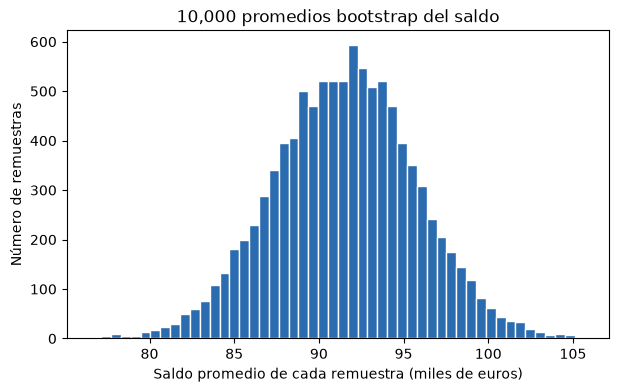

Asimetría de los promedios bootstrap (0 = simétrico): -0.029


In [5]:
generador = np.random.default_rng(7)
remuestras = generador.choice(saldo_abandona.to_numpy(), size=(10000, n_saldo), replace=True)
promedios_bootstrap = remuestras.mean(axis=1)
figura, eje = plt.subplots(figsize=(7, 4))
eje.hist(promedios_bootstrap / 1000, bins=50, color="#2b6cb0", edgecolor="white")
eje.set_xlabel("Saldo promedio de cada remuestra (miles de euros)")
eje.set_ylabel("Número de remuestras")
eje.set_title("10,000 promedios bootstrap del saldo")
plt.show()
asimetria_promedios = stats.skew(promedios_bootstrap)
print("Asimetría de los promedios bootstrap (0 = simétrico):", round(asimetria_promedios, 3))

**Resultado:** los promedios forman una campana simétrica (asimetría cercana a 0). El supuesto de normalidad de la media se cumple.

### Cálculo paso a paso

In [6]:
media_saldo = saldo_abandona.mean()
desviacion_saldo = saldo_abandona.std()
error_estandar_saldo = desviacion_saldo / np.sqrt(n_saldo)
error_estandar_saldo_corregido = error_estandar_saldo * fcpf
t_critico_saldo = stats.t.ppf(0.975, n_saldo - 1)
margen_saldo = t_critico_saldo * error_estandar_saldo_corregido
limite_inferior_saldo = media_saldo - margen_saldo
limite_superior_saldo = media_saldo + margen_saldo
print("Media del saldo (x barra):", round(media_saldo, 2))
print("Desviación estándar (s):", round(desviacion_saldo, 2))
print("Error estándar:", round(error_estandar_saldo, 2))
print("Error estándar corregido (por FCPF):", round(error_estandar_saldo_corregido, 2))
print("Valor crítico t:", round(t_critico_saldo, 4))
print("Margen de error:", round(margen_saldo, 2))
print("Intervalo de confianza al 95 % para la media del saldo:", (float(round(limite_inferior_saldo, 2)), float(round(limite_superior_saldo, 2))))

Media del saldo (x barra): 91561.53
Desviación estándar (s): 60592.91
Error estándar: 4221.71
Error estándar corregido (por FCPF): 4005.26
Valor crítico t: 1.9716
Margen de error: 7896.79
Intervalo de confianza al 95 % para la media del saldo: (83664.74, 99458.33)


**Comprobación con scipy:**

In [7]:
intervalo_scipy_saldo = stats.t.interval(0.95, n_saldo - 1, loc=media_saldo, scale=error_estandar_saldo_corregido)
print("Intervalo calculado con scipy:", (float(round(intervalo_scipy_saldo[0], 2)), float(round(intervalo_scipy_saldo[1], 2))))

Intervalo calculado con scipy: (83664.74, 99458.33)


**Interpretación (así se escribe en el reporte):**
> Con un nivel de confianza del 95 %, el saldo promedio de los clientes del banco que abandonan está entre **83,665 € y 99,458 €**.

### Otras formas válidas de hacerlo

| Método | A favor | En contra |
|---|---|---|
| **Intervalo t** (el del proyecto) | Es la fórmula del documento; se calcula a mano | Depende del Teorema del Límite Central (aquí se cumple, n = 206) |
| **Intervalo bootstrap** | No supone ninguna forma de los datos | Requiere computadora; no viene en el documento |
| **Intervalo para la mediana** | Describe mejor a un cliente típico cuando hay muchos ceros | Responde otra pregunta: la mediana no sirve para calcular el dinero total que se pierde |

El proyecto usa el intervalo t porque la pregunta P2 es sobre el **promedio**, que es el que sirve para calcular el dinero total en riesgo (Día 6).

---
## Paso 3 · P3: intervalo para la diferencia de proporciones (inactivos − activos)

$$IC = (\hat p_1 - \hat p_2) \pm z_{\alpha/2}\sqrt{\frac{\hat p_1(1-\hat p_1)}{n_1} + \frac{\hat p_2(1-\hat p_2)}{n_2}}\cdot\text{FCPF}$$

| Símbolo | Qué es |
|---|---|
| $\hat p_1$, $n_1$ | Proporción de abandono y tamaño del grupo de **inactivos** |
| $\hat p_2$, $n_2$ | Proporción de abandono y tamaño del grupo de **activos** |
| La raíz | Error estándar de la diferencia. Las varianzas de los dos grupos **se suman**, porque las dos proporciones tienen error de muestreo |

### Revisión de supuestos

| Supuesto | ¿Se cumple? |
|---|---|
| Muestra aleatoria | Sí |
| Grupos independientes | Sí: un cliente es activo o inactivo, nunca los dos |
| Al menos 10 casos de cada resultado en cada grupo | Se comprueba abajo |

In [8]:
abandono_inactivos = muestra.loc[muestra["miembro_activo"] == 0, "abandono"]
abandono_activos = muestra.loc[muestra["miembro_activo"] == 1, "abandono"]
n_inactivos = len(abandono_inactivos)
n_activos = len(abandono_activos)
abandonos_inactivos = abandono_inactivos.sum()
abandonos_activos = abandono_activos.sum()
print("Inactivos: n =", n_inactivos, "| abandonan:", abandonos_inactivos, "| se quedan:", n_inactivos - abandonos_inactivos)
print("Activos: n =", n_activos, "| abandonan:", abandonos_activos, "| se quedan:", n_activos - abandonos_activos)

Inactivos: n = 463 | abandonan: 123 | se quedan: 340
Activos: n = 537 | abandonan: 83 | se quedan: 454


Todos los conteos son mayores a 10. Se cumple.

### Cálculo paso a paso

In [9]:
p_inactivos = abandonos_inactivos / n_inactivos
p_activos = abandonos_activos / n_activos
diferencia_p = p_inactivos - p_activos
varianza_inactivos = p_inactivos * (1 - p_inactivos) / n_inactivos
varianza_activos = p_activos * (1 - p_activos) / n_activos
error_estandar_diferencia_p = np.sqrt(varianza_inactivos + varianza_activos)
error_estandar_diferencia_p_corregido = error_estandar_diferencia_p * fcpf
margen_diferencia_p = z_critico * error_estandar_diferencia_p_corregido
limite_inferior_p = diferencia_p - margen_diferencia_p
limite_superior_p = diferencia_p + margen_diferencia_p
print("Proporción de abandono en inactivos:", round(p_inactivos, 4))
print("Proporción de abandono en activos:", round(p_activos, 4))
print("Diferencia de proporciones:", round(diferencia_p, 4))
print("Error estándar de la diferencia (corregido):", round(error_estandar_diferencia_p_corregido, 4))
print("Margen de error:", round(margen_diferencia_p, 4))
print("Intervalo de confianza al 95 % para la diferencia:", (float(round(limite_inferior_p, 4)), float(round(limite_superior_p, 4))))

Proporción de abandono en inactivos: 0.2657
Proporción de abandono en activos: 0.1546
Diferencia de proporciones: 0.1111
Error estándar de la diferencia (corregido): 0.0245
Margen de error: 0.0479
Intervalo de confianza al 95 % para la diferencia: (0.0632, 0.159)


### Cómo se lee el intervalo de una diferencia: ¿contiene el 0?

- Si el intervalo **contiene el 0**, una diferencia de cero (los dos grupos abandonan igual) es un valor posible.
- Si el intervalo **no contiene el 0**, los datos indican que hay una diferencia en la población.

**Interpretación (así se escribe en el reporte):**
> Con un nivel de confianza del 95 %, la proporción de abandono de los clientes inactivos es entre **6.3 y 15.9 puntos porcentuales mayor** que la de los clientes activos. El intervalo no contiene el 0.

### La prueba de hipótesis equivalente

Un intervalo al 95 % que no contiene el 0 equivale a rechazar, con α = 0.05, la hipótesis de que no hay diferencia. Se hace la prueba para reportar el p-valor.

- **H0:** la proporción de abandono de inactivos es igual a la de activos ($p_1 = p_2$).
- **H1:** las proporciones son distintas ($p_1 \neq p_2$).
- **Nivel de significancia:** α = 0.05.
- **Prueba:** prueba z para dos proporciones. Los supuestos son los mismos que los del intervalo y ya se revisaron.

Bajo H0, las dos proporciones son iguales, así que se estima una sola proporción combinada con los dos grupos.

In [10]:
p_combinada = (abandonos_inactivos + abandonos_activos) / (n_inactivos + n_activos)
error_estandar_bajo_h0 = np.sqrt(p_combinada * (1 - p_combinada) * (1 / n_inactivos + 1 / n_activos))
estadistico_z = diferencia_p / error_estandar_bajo_h0
p_valor_proporciones = 2 * (1 - stats.norm.cdf(abs(estadistico_z)))
print("Proporción combinada:", round(p_combinada, 4))
print("Estadístico z:", round(estadistico_z, 3))
print("p-valor:", p_valor_proporciones)

Proporción combinada: 0.206
Estadístico z: 4.331
p-valor: 1.481284697346652e-05


**Conclusión:** Se rechaza H0 (p < 0.001 < 0.05): la proporción de abandono de los clientes inactivos es mayor que la de los activos.

### Tamaño del efecto: ¿la diferencia es importante en la práctica?

El p-valor dice si la diferencia **existe**; no dice si es **grande**. Para eso se mide el tamaño del efecto:

In [11]:
razon_de_riesgo = p_inactivos / p_activos
print("Diferencia en puntos porcentuales:", round(diferencia_p * 100, 1))
print("Razón de riesgo (proporción inactivos / proporción activos):", round(razon_de_riesgo, 2))

Diferencia en puntos porcentuales: 11.1
Razón de riesgo (proporción inactivos / proporción activos): 1.72


**Importancia práctica:** los inactivos abandonan 11.1 puntos porcentuales más, es decir, **1.72 veces** lo que abandonan los activos. Es una diferencia grande para un banco: en un grupo de unos 4,600 clientes inactivos, 11 puntos son unos 500 clientes.

**Advertencia:** que la diferencia exista no prueba que la inactividad **cause** el abandono. Es un estudio observacional: sólo se observó a los clientes, no se hizo un experimento. Un cliente puede dejar de usar su cuenta porque ya decidió irse.

---
## Paso 4 · P4: intervalo para la diferencia de medias (edad)

$$IC = (\bar x_1 - \bar x_2) \pm t_{\alpha/2,\,gl}\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}\cdot\text{FCPF}$$

| Símbolo | Qué es |
|---|---|
| $\bar x_1$, $s_1$, $n_1$ | Edad promedio, desviación estándar y tamaño del grupo que **abandonó** |
| $\bar x_2$, $s_2$, $n_2$ | Lo mismo para el grupo que **se quedó** |
| $s^2$ | Varianza (desviación estándar al cuadrado) |
| $gl$ | Grados de libertad de Welch (se calculan abajo) |

### Revisión de supuestos

In [12]:
edad_se_va = muestra.loc[muestra["abandono"] == 1, "edad"]
edad_se_queda = muestra.loc[muestra["abandono"] == 0, "edad"]
n_se_va = len(edad_se_va)
n_se_queda = len(edad_se_queda)
print("Tamaño del grupo que abandonó:", n_se_va)
print("Tamaño del grupo que se quedó:", n_se_queda)
print("Asimetría de la edad, grupo que abandonó (0 = simétrica):", round(stats.skew(edad_se_va), 2))
print("Asimetría de la edad, grupo que se quedó (0 = simétrica):", round(stats.skew(edad_se_queda), 2))

Tamaño del grupo que abandonó: 206
Tamaño del grupo que se quedó: 794
Asimetría de la edad, grupo que abandonó (0 = simétrica): 0.16
Asimetría de la edad, grupo que se quedó (0 = simétrica): 1.37


| Supuesto | ¿Se cumple? |
|---|---|
| Muestra aleatoria | Sí |
| Grupos independientes | Sí: un cliente abandonó o se quedó, no ambos |
| Normalidad de las medias | Sí. La edad del grupo que abandonó es casi simétrica (asimetría 0.16). La del grupo que se quedó tiene asimetría moderada (1.37: algunos clientes mayores alargan la cola derecha), pero ese grupo tiene 794 datos. Con más de 30 datos por grupo aplica el Teorema del Límite Central |
| Igualdad de varianzas | Se revisa con la prueba de Levene |

**Nota sobre pruebas de normalidad:** existen pruebas como la de Shapiro-Wilk, pero con cientos de datos detectan diferencias mínimas con la campana y casi siempre rechazan la normalidad, aunque no afecten al intervalo. Por eso aquí se usa el tamaño de muestra y la asimetría.

### Prueba de Levene: ¿los dos grupos tienen la misma varianza?

- **H0:** las varianzas de la edad en los dos grupos son iguales.
- **H1:** las varianzas son distintas.
- **Nivel de significancia:** α = 0.05.

In [13]:
resultado_levene = stats.levene(edad_se_va, edad_se_queda)
print("Desviación estándar, grupo que abandonó:", round(edad_se_va.std(), 2))
print("Desviación estándar, grupo que se quedó:", round(edad_se_queda.std(), 2))
print("Estadístico de Levene:", round(resultado_levene.statistic, 3))
print("p-valor de Levene:", round(resultado_levene.pvalue, 3))

Desviación estándar, grupo que abandonó: 9.24
Desviación estándar, grupo que se quedó: 9.94
Estadístico de Levene: 0.012
p-valor de Levene: 0.913


**Conclusión de Levene:** No se rechaza H0 (p = 0.913 ≥ 0.05): no hay evidencia de que las varianzas de la edad sean distintas en los dos grupos (desviaciones estándar de 9.24 y 9.94 años).

### ¿Por qué el método de Welch?

Hay dos fórmulas para comparar dos medias:

| Método | A favor | En contra |
|---|---|---|
| **t con varianza combinada** (clásico) | Un poco más preciso **si** las varianzas son iguales | Da resultados incorrectos si las varianzas son distintas |
| **t de Welch** (el del proyecto) | Es correcto con varianzas iguales o distintas | Sus grados de libertad tienen una fórmula más larga |

El proyecto usa **Welch** porque es válido en los dos casos: no depende del resultado de Levene. Como aquí las varianzas resultaron parecidas, los dos métodos dan casi el mismo intervalo.

### Grados de libertad de Welch

$$gl = \frac{\left(\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}\right)^2}{\frac{(s_1^2/n_1)^2}{n_1 - 1} + \frac{(s_2^2/n_2)^2}{n_2 - 1}}$$

### Cálculo paso a paso

In [14]:
media_se_va = edad_se_va.mean()
media_se_queda = edad_se_queda.mean()
diferencia_medias = media_se_va - media_se_queda
varianza_media_se_va = edad_se_va.var() / n_se_va
varianza_media_se_queda = edad_se_queda.var() / n_se_queda
numerador_gl = (varianza_media_se_va + varianza_media_se_queda) ** 2
denominador_gl = varianza_media_se_va ** 2 / (n_se_va - 1) + varianza_media_se_queda ** 2 / (n_se_queda - 1)
grados_libertad = numerador_gl / denominador_gl
t_critico_welch = stats.t.ppf(0.975, grados_libertad)
error_estandar_diferencia = np.sqrt(varianza_media_se_va + varianza_media_se_queda)
error_estandar_diferencia_corregido = error_estandar_diferencia * fcpf
margen_diferencia = t_critico_welch * error_estandar_diferencia_corregido
limite_inferior_edad = diferencia_medias - margen_diferencia
limite_superior_edad = diferencia_medias + margen_diferencia
print("Edad promedio, grupo que abandonó:", round(media_se_va, 2))
print("Edad promedio, grupo que se quedó:", round(media_se_queda, 2))
print("Diferencia de medias:", round(diferencia_medias, 2))
print("Grados de libertad de Welch:", round(grados_libertad, 1))
print("Valor crítico t:", round(t_critico_welch, 4))
print("Error estándar de la diferencia (corregido):", round(error_estandar_diferencia_corregido, 4))
print("Margen de error:", round(margen_diferencia, 2))
print("Intervalo de confianza al 95 % para la diferencia de edades:", (float(round(limite_inferior_edad, 2)), float(round(limite_superior_edad, 2))))

Edad promedio, grupo que abandonó: 46.5
Edad promedio, grupo que se quedó: 37.1
Diferencia de medias: 9.41
Grados de libertad de Welch: 338.6
Valor crítico t: 1.967
Error estándar de la diferencia (corregido): 0.6963
Margen de error: 1.37
Intervalo de confianza al 95 % para la diferencia de edades: (8.04, 10.78)


**Comprobación con scipy.** La función de scipy no aplica el FCPF, así que se compara contra nuestro cálculo sin esa corrección:

In [15]:
margen_sin_correccion = t_critico_welch * error_estandar_diferencia
intervalo_propio_sin_correccion = (diferencia_medias - margen_sin_correccion, diferencia_medias + margen_sin_correccion)
intervalo_scipy_edad = stats.ttest_ind(edad_se_va, edad_se_queda, equal_var=False).confidence_interval(0.95)
print("Intervalo propio sin FCPF:", (float(round(intervalo_propio_sin_correccion[0], 2)), float(round(intervalo_propio_sin_correccion[1], 2))))
print("Intervalo de scipy:", (float(round(intervalo_scipy_edad.low, 2)), float(round(intervalo_scipy_edad.high, 2))))

Intervalo propio sin FCPF: (7.96, 10.85)
Intervalo de scipy: (7.96, 10.85)


**Interpretación (así se escribe en el reporte):**
> Con un nivel de confianza del 95 %, la edad promedio de los clientes que abandonan es entre **8.0 y 10.8 años mayor** que la de quienes se quedan. El intervalo no contiene el 0.

### La prueba de hipótesis equivalente: prueba t de Welch

- **H0:** la edad promedio de quienes abandonan es igual a la de quienes se quedan ($\mu_1 = \mu_2$).
- **H1:** las edades promedio son distintas ($\mu_1 \neq \mu_2$).
- **Nivel de significancia:** α = 0.05.

In [16]:
resultado_welch = stats.ttest_ind(edad_se_va, edad_se_queda, equal_var=False)
print("Estadístico t:", round(resultado_welch.statistic, 3))
print("p-valor:", resultado_welch.pvalue)

Estadístico t: 12.817
p-valor: 6.235668920121681e-31


**Conclusión:** Se rechaza H0 (p < 0.001 < 0.05): la edad promedio de los clientes que abandonan es mayor que la de los que se quedan.

### Tamaño del efecto: d de Cohen

La **d de Cohen** expresa la diferencia de medias en unidades de desviación estándar. Referencias usuales: 0.2 = efecto pequeño, 0.5 = mediano, 0.8 o más = grande.

In [17]:
varianza_combinada = ((n_se_va - 1) * edad_se_va.var() + (n_se_queda - 1) * edad_se_queda.var()) / (n_se_va + n_se_queda - 2)
desviacion_combinada = np.sqrt(varianza_combinada)
d_de_cohen = diferencia_medias / desviacion_combinada
print("Desviación estándar combinada:", round(desviacion_combinada, 2))
print("d de Cohen:", round(d_de_cohen, 2))

Desviación estándar combinada: 9.8
d de Cohen: 0.96


**Importancia práctica:** la d de Cohen es cercana a 1: la diferencia de edades es **grande** (casi una desviación estándar completa). No es sólo estadísticamente significativa; también es relevante para el banco.

---
## Paso 5 · Resumen de los cuatro intervalos

In [18]:
resumen = pd.DataFrame({
    "Pregunta": ["P1 · proporción de abandono", "P2 · saldo promedio de quien abandona", "P3 · inactivos - activos", "P4 · edad: se va - se queda"],
    "Estimación puntual": [0.206, round(media_saldo, 2), round(diferencia_p, 4), round(diferencia_medias, 2)],
    "Límite inferior": [0.1822, round(limite_inferior_saldo, 2), round(limite_inferior_p, 4), round(limite_inferior_edad, 2)],
    "Límite superior": [0.2298, round(limite_superior_saldo, 2), round(limite_superior_p, 4), round(limite_superior_edad, 2)],
})
print(resumen.to_string(index=False))

                             Pregunta  Estimación puntual  Límite inferior  Límite superior
          P1 · proporción de abandono              0.2060           0.1822           0.2298
P2 · saldo promedio de quien abandona          91561.5300       83664.7400       99458.3300
             P3 · inactivos - activos              0.1111           0.0632           0.1590
          P4 · edad: se va - se queda              9.4100           8.0400          10.7800

---
## Preguntas que puede hacer el profesor (apartado 5)

**1. ¿Por qué usaron cuatro técnicas si el documento pide dos?**
Cada pregunta del proyecto necesita una técnica distinta según su tipo de variable, y el documento menciona las cuatro como opciones.

**2. ¿Por qué el intervalo del saldo usa t y no z?**
Porque no se conoce la desviación estándar del saldo en la población; se estima con la de la muestra. La distribución t compensa esa incertidumbre.

**3. Los saldos no son normales. ¿Por qué usaron una fórmula que supone normalidad?**
La fórmula supone que el **promedio** es normal, no los datos. Con 206 datos, el Teorema del Límite Central lo garantiza, y lo comprobamos con un bootstrap: los 10,000 promedios forman una campana.

**4. ¿Qué es el bootstrap?**
Sacar muchas muestras nuevas de la propia muestra, con reemplazo, y calcular el promedio de cada una para ver cómo varía.

**5. Interpreten el intervalo de P3.**
Con 95 % de confianza, los inactivos abandonan entre 6.3 y 15.9 puntos porcentuales más que los activos. No contiene el 0: hay diferencia en la población.

**6. ¿Eso prueba que la inactividad causa el abandono?**
No. Es un estudio observacional. Sólo muestra que las dos cosas ocurren juntas.

**7. ¿Qué es el método de Welch y por qué lo usaron?**
Es la forma de comparar dos medias sin suponer que los grupos tienen la misma varianza. Es válido tanto si las varianzas son iguales como si no.

**8. ¿Qué significa que el intervalo de una diferencia no contenga el 0?**
Que una diferencia de cero no es un valor compatible con los datos al 95 % de confianza. Equivale a rechazar H0 con α = 0.05.

**9. ¿Qué diferencia hay entre significancia estadística e importancia práctica?**
La significancia (p-valor) dice si la diferencia existe. La importancia práctica (tamaño del efecto) dice si es grande. En P4 hay las dos: p < 0.001 y d de Cohen cercana a 1.

**10. ¿Por qué aplicaron la corrección por población finita en las diferencias?**
Porque cada grupo de la muestra es cerca del 10 % de su grupo en la población, por el muestreo aleatorio.

---
## Tarea del Día 4 (para todo el equipo)

Repartan las preguntas P2, P3 y P4 entre los integrantes. Cada uno explica en voz alta, sin leer: la fórmula de su pregunta, los supuestos que se revisaron y la interpretación del intervalo.

➡️ **Día 5:** Apartado 6 · Análisis e interpretación.